In [ ]:
# 1E. Build Feedforward Neural Network (FNN) with Keras and TensorFlow for
# classification of Sign Language MNIST image dataset using the following steps:
# a. Import the necessary packages
# b. Load the training and testing data
# c. Define the network architecture using Keras
# d. Train the model using SGD/Adam optimizer
# e. Evaluate the network
# f. Plot the training loss and accuracy

# Load → Normalize → Encode → Build → Compile → Train → Evaluate → Predict → Plot

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelBinarizer

In [2]:
# Load
train_data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test_data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

x_train = train_data.drop("label" , axis = 1).values.reshape(-1 , 28 , 28 , 1)
x_test = test_data.drop("label" , axis = 1).values.reshape(-1 , 28 , 28 , 1)
y_train = train_data["label"].values
y_test = test_data["label"].values

In [3]:
# Normalize : 

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

lb = LabelBinarizer()
y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)

In [4]:
model = keras.Sequential([
    keras.layers.Input(shape= x_train.shape[1:]),
    keras.layers.Flatten(),
    keras.layers.Dense(128 , activation="relu"),
    keras.layers.Dense(24 , activation="softmax")
])

In [5]:
# Compile : 
model.compile(optimizer= keras.optimizers.SGD(learning_rate=0.01) , loss="categorical_crossentropy" , metrics=["accuracy"])

In [6]:
# Train : 
history = model.fit(
    x_train , y_train , epochs = 11 , batch_size = 32 , validation_split = 0.2
)

Epoch 1/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 1s 665us/step - accuracy: 0.2372 - loss: 2.8037 - val_accuracy: 0.3810 - val_loss: 2.3998
Epoch 2/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 0s 542us/step - accuracy: 0.4470 - loss: 2.1189 - val_accuracy: 0.4323 - val_loss: 1.8943
Epoch 3/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 0s 549us/step - accuracy: 0.5494 - loss: 1.6970 - val_accuracy: 0.5143 - val_loss: 1.5613
Epoch 4/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 0s 546us/step - accuracy: 0.6093 - loss: 1.4378 - val_accuracy: 0.5859 - val_loss: 1.3775
Epoch 5/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 0s 546us/step - accuracy: 0.6612 - loss: 1.2566 - val_accuracy: 0.6811 - val_loss: 1.1791
Epoch 6/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 0s 545us/step - accuracy: 0.6960 - loss: 1.1224 - val_accuracy: 0.6775 - val_loss: 1.0550
Epoch 7/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 0s 541us/step - accuracy: 0.7209 - loss: 1.0178 - val_accuracy: 0.6849 - val_loss: 1.0453
Epoch 8/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 0s 546us/step - accuracy: 0.7482 - loss: 0.9291 - 

In [7]:
# Evaluate : 
loss , accuracy = model.evaluate(x_test , y_test , verbose = 0)
print(loss)
print(accuracy)

1.1427677869796753
0.6712214350700378


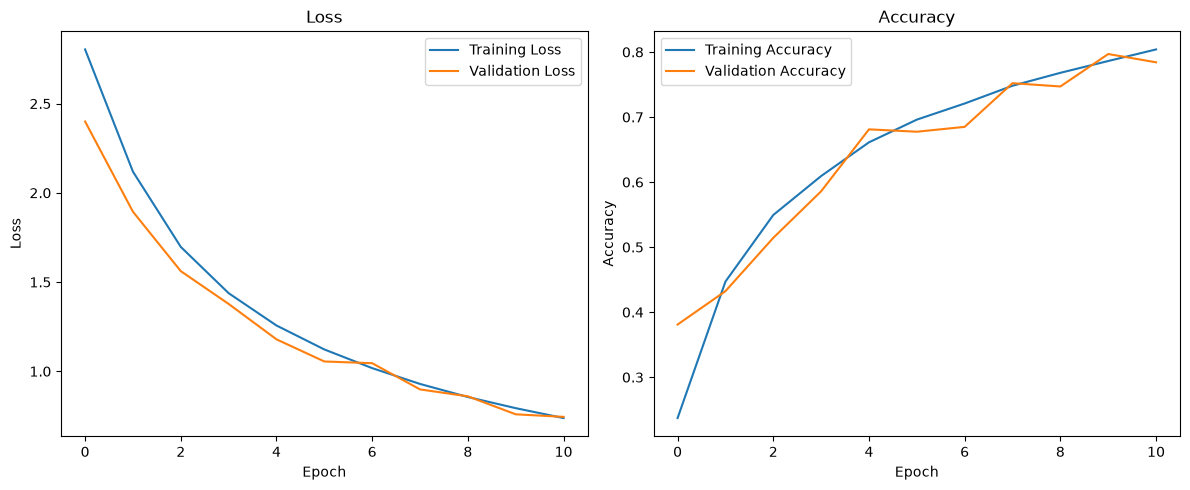

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()